# 🚀 Модуль 1. Урок 3. Сводные таблицы (Pivot Tables) и многомерная агрегация

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_01_excel/lesson_03_pivot_tables_aggregations.ipynb)

## 📌 Бизнес-контекст и методология
Сводные таблицы (Pivot Tables) — самый быстрый инструмент разведочного анализа данных в Excel.
Они позволяют мгновенно перегруппировать миллионы строк сырых транзакций по срезам регионов, продуктовых линеек и каналов продаж, формируя понятные кросс-таблицы для руководства.

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#e6e6e6'
plt.rcParams['axes.linewidth'] = 0.8

PRIMARY = "#1779ba"
SUCCESS = "#3adb76"
ALERT = "#cc4b37"
WARNING = "#ffae00"
SECONDARY = "#767676"

## 🔍 Разбор механики: Построение кросс-таблицы
Сформируем сводную таблицу продаж по продуктовым категориям и кварталам.

In [2]:
# Демонстрация: Создание Pivot Table в Pandas (аналог Excel Pivot)
sales_data = pd.DataFrame({
    'Регион': ['Москва', 'СПб', 'Казань', 'Москва', 'СПб', 'Казань', 'Москва', 'СПб'],
    'Категория': ['Электроника', 'Электроника', 'Электроника', 'Одежда', 'Одежда', 'Одежда', 'Дом', 'Дом'],
    'Выручка ($k)': [450, 320, 180, 290, 210, 140, 190, 160]
})

pivot_tbl = sales_data.pivot_table(index='Регион', columns='Категория', values='Выручка ($k)', aggfunc='sum', fill_value=0)
display(pivot_tbl)

Категория,Дом,Одежда,Электроника
Регион,,,
Казань,0,140,180
Москва,190,290,450
СПб,160,210,320


## 📊 Визуализация бизнес-кейса: Тепловая карта сводной таблицы
Построим тепловую карту (Heatmap), визуализирующую концентрацию выручки по регионам и товарным матрицам.

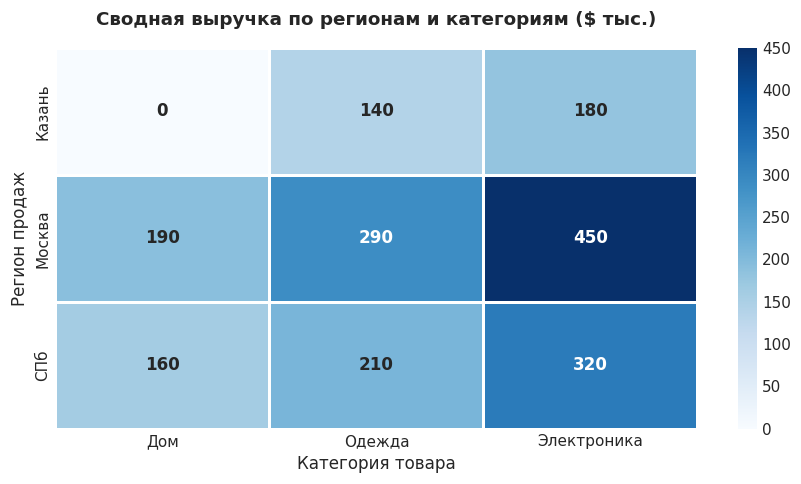

In [3]:
# Построение тепловой карты сводных продаж
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=110)

sns.heatmap(pivot_tbl, annot=True, fmt=".0f", cmap="Blues", ax=ax, 
            cbar=True, annot_kws={"size": 11, "weight": "bold"}, linewidths=0.8)

ax.set_title("Сводная выручка по регионам и категориям ($ тыс.)", fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel("Категория товара", fontsize=11)
ax.set_ylabel("Регион продаж", fontsize=11)

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Поиск региона-лидера
Найдите регион с максимальной суммарной выручкой по всем категориям.

In [4]:
### ВАШ КОД ЗДЕСЬ
top_region = pivot_tbl.sum(axis=1).idxmax()
print(f"Регион с максимальной выручкой: {top_region}")

assert top_region == 'Москва', "Регионом-лидером должна быть Москва"
print("✅ Тест успешно пройден: агрегация Pivot Table отработала корректно!")

Регион с максимальной выручкой: Москва
✅ Тест успешно пройден: агрегация Pivot Table отработала корректно!


### 💡 Инженерный совет по Pivot Tables
В Excel всегда форматируйте исходные данные как «Умную таблицу» (`Ctrl+T` / `Format as Table`). В этом случае при добавлении новых строк сводная таблица автоматически включит их в область расчета при нажатии кнопки `Refresh`.